In [1]:
import pandas as pd
import numpy as np
from sklearn import linear_model
import matplotlib.pyplot as plt

In [7]:
df = pd.read_csv('homepricesmulti.csv',sep='\t')

In [22]:
df.head()

,area,bedrooms,age,price
0,2600,3.0,20,550000
1,3000,4.0,15,565000
2,3200,4.2,18,610000
3,3600,3.0,30,595000
4,4000,5.0,8,760000


In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   area      6 non-null      int64  
 1   bedrooms  6 non-null      float64
 2   age       6 non-null      int64  
 3   price     6 non-null      int64  
dtypes: float64(1), int64(3)
memory usage: 324.0 bytes


In [25]:
df.shape
df.isnull().sum()

area        0
bedrooms    0
age         0
price       0
dtype: int64

In [28]:
#4. Trouvez le prix d'une maison de 3000 m², 3 chambres, 40 ans d'âge
df.query('area >= 3000 and bedrooms >= 3 and age <= 40')

,area,bedrooms,age,price
1,3000,4.0,15,565000
2,3200,4.2,18,610000
3,3600,3.0,30,595000
4,4000,5.0,8,760000
5,4100,6.0,8,810000


In [31]:
model = linear_model.LinearRegression()
model.fit(df[['area','bedrooms','age']],df[['price']])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 3)","[[ 116.67,18756.29,-3675.75]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['area','bedrooms','age']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[231586.01]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [36]:
from joblib import dump, load
dump(model,'model_multi.pkl')
loaded = load('model_multi.pkl')
new_predict_price = loaded.predict([[4000,3,20]])
print(new_predict_price)

[[681017.87028475]]


C:\Users\user\PycharmProjects\Tps_AI\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


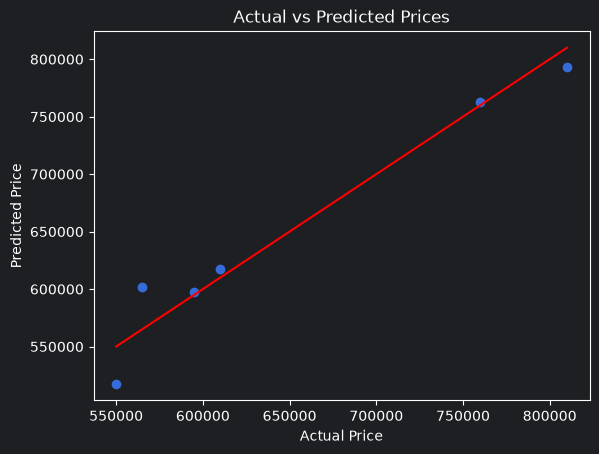

In [38]:
y_pred = model.predict(df[['area', 'bedrooms', 'age']])

plt.scatter(df['price'], y_pred)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Prices')

# Perfect prediction reference line
plt.plot(
    [df['price'].min(), df['price'].max()],
    [df['price'].min(), df['price'].max()],
    color='red'
)

plt.show()

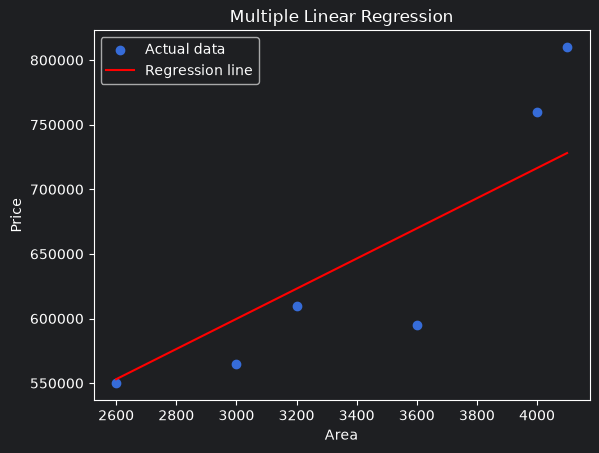

In [40]:
# Generate area values
area_values = np.linspace(df['area'].min(), df['area'].max(), 100)

# Keep other features constant
bedrooms = df['bedrooms'].mean()
age = df['age'].mean()
# Create input data
X = pd.DataFrame({
    'area': area_values,
    'bedrooms': bedrooms,
    'age': age
})

# Predict prices
predictions = model.predict(X)

# Plot
plt.scatter(df['area'], df['price'], label='Actual data')
plt.plot(area_values, predictions, color='red', label='Regression line')

plt.xlabel('Area')
plt.ylabel('Price')
plt.title('Multiple Linear Regression')
plt.legend()
plt.show()